In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, IFrame, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
RES = ROOT / "results"
def show_png(path, width=620):
    display(Image(filename=str(path), width=width))

# 01 · Dataset exploration (EDA)
Partitions used: **train** (80 trips) and **student_test** (10 trips). `eval_test` is never read here.
Everything below is loaded from `results/eda/` (produced by `python -m visualisations.eda_plots`,
`python -m data_processing.inspect_network`, `python -m data_processing.label_points` and `python -m features.miss_report`).

## 1. Inventory: trips and GPS observations per partition

In [2]:
display(pd.read_csv(RES / "eda/inventory_summary.csv"))
display(pd.read_csv(RES / "eda/inventory.csv").head(8))

,split,size,min,median,max,sum
0,student_test,10,262,1420.0,3958,19160
1,train,80,361,1529.0,19313,208417


,split,trip_id,gps_points,missing_files,track_bytes,nodes_bytes,arcs_bytes,route_bytes
0,train,1,1315,NaN,40975,1776180,2114264,3644
1,train,2,7243,NaN,238085,166656,172658,1660
2,train,3,821,NaN,26164,191898,193761,490
3,train,4,1064,NaN,34982,154350,165237,1902
4,train,5,1045,NaN,33378,18858,13930,526
5,train,6,1450,NaN,47576,68439,69671,1445
6,train,8,3093,NaN,104055,109890,109571,1005
7,train,10,2711,NaN,88356,178542,168903,1252


## 2. Missing / invalid values and time gaps (`quality.csv`)

In [3]:
q = pd.read_csv(RES / "eda/quality.csv")
display(q.head(6))
num = q.select_dtypes("number")
display(num.groupby(q["split"]).sum().T)

,split,trip_id,missing_values,invalid_coordinates,invalid_timestamps,duplicate_timestamps,non_increasing_steps,steps,one_second_steps,gaps_over_5s,largest_gap_s,duration_s,length_m,share_one_second
0,train,1,0,0,0,0,0,1314,1289,1,16.0,1357.000,50228.554965,0.980974
1,train,2,0,0,0,0,0,7242,7058,78,160.0,8933.156,55950.970738,0.974593
2,train,3,0,0,0,0,0,820,817,0,2.0,823.000,8439.391569,0.996341
3,train,4,0,0,0,0,0,1063,572,320,51.0,5217.000,27945.595454,0.538100
4,train,5,0,0,0,0,0,1044,1044,0,1.0,1044.000,31346.423594,1.000000
5,train,6,0,0,0,0,0,1449,1437,9,301.0,2102.000,19434.427843,0.991718


split,student_test,train
trip_id,473.000000,3.963000e+03
missing_values,0.000000,0.000000e+00
invalid_coordinates,0.000000,0.000000e+00
invalid_timestamps,0.000000,0.000000e+00
duplicate_timestamps,0.000000,0.000000e+00
non_increasing_steps,0.000000,0.000000e+00
steps,19150.000000,2.083370e+05
one_second_steps,18886.000000,2.010530e+05
gaps_over_5s,44.000000,1.216000e+03
largest_gap_s,255.000000,2.165120e+05


## 3. Road-network size and connectivity (`network_stats.csv`) and the network check

In [4]:
display(pd.read_csv(RES / "eda/network_stats.csv").head(8))
print((RES / "eda/network_check.txt").read_text())

,split,trip_id,nodes,arcs,weak_components,isolated_nodes,reference_arcs,reference_connected_share
0,train,1,88809,165790,175,0,525,1.000000
1,train,2,7936,16139,14,0,262,0.996169
2,train,3,9138,18028,42,0,79,1.000000
3,train,4,7350,15499,12,0,320,1.000000
4,train,5,898,1579,3,0,105,1.000000
5,train,6,3259,6757,8,0,261,1.000000
6,train,8,4995,10421,13,0,173,1.000000
7,train,10,8502,15715,28,0,210,1.000000


trips checked (train + student_test): 90
distinct .nodes files: 90  distinct .arcs files: 90
road network: PER-TRIP (differs between trips)
arcs whose reverse (to->from) also exists: 3747676/4060042 = 92.3%  (high => mostly two-way; low => one-way)
route arc_ids not present in .arcs: 0/34813
consecutive route arcs that connect (to_node == next from_node): 34709/34723 = 100.0%



## 4. GPS noise (distance to the nearest road segment)

In [5]:
g = pd.read_csv(RES / "eda/gps_noise.csv")
display(g[g["trip_id"] == "all"])

,split,trip_id,n_points,median_m,p95_m
80,train,all,208417,4.970126,83.433914
91,student_test,all,19160,4.758668,15.999087


## 5. Figures (train and student_test)

eda_coordinates_student_test.png


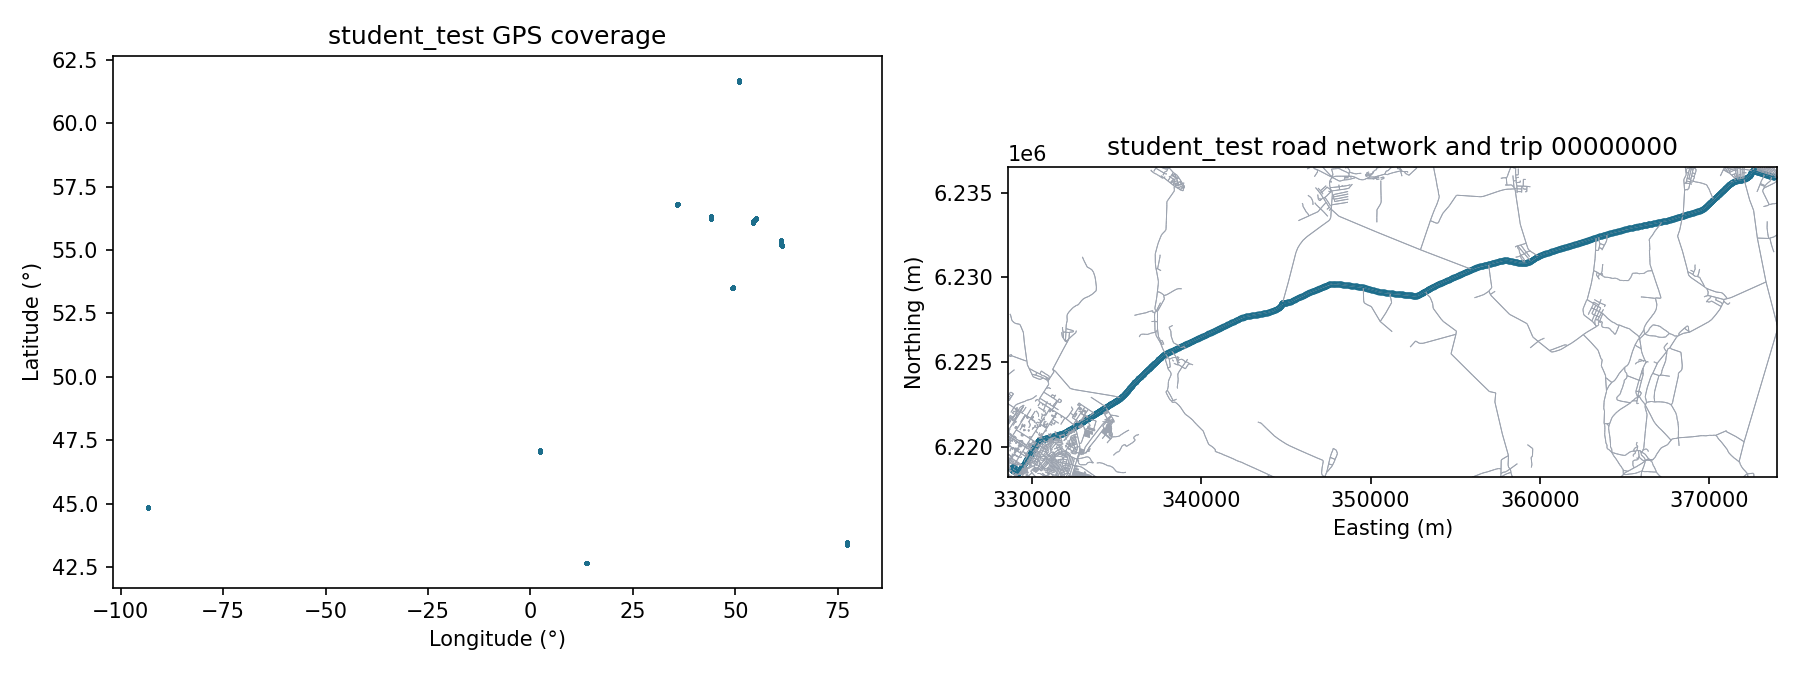

eda_coordinates_train.png


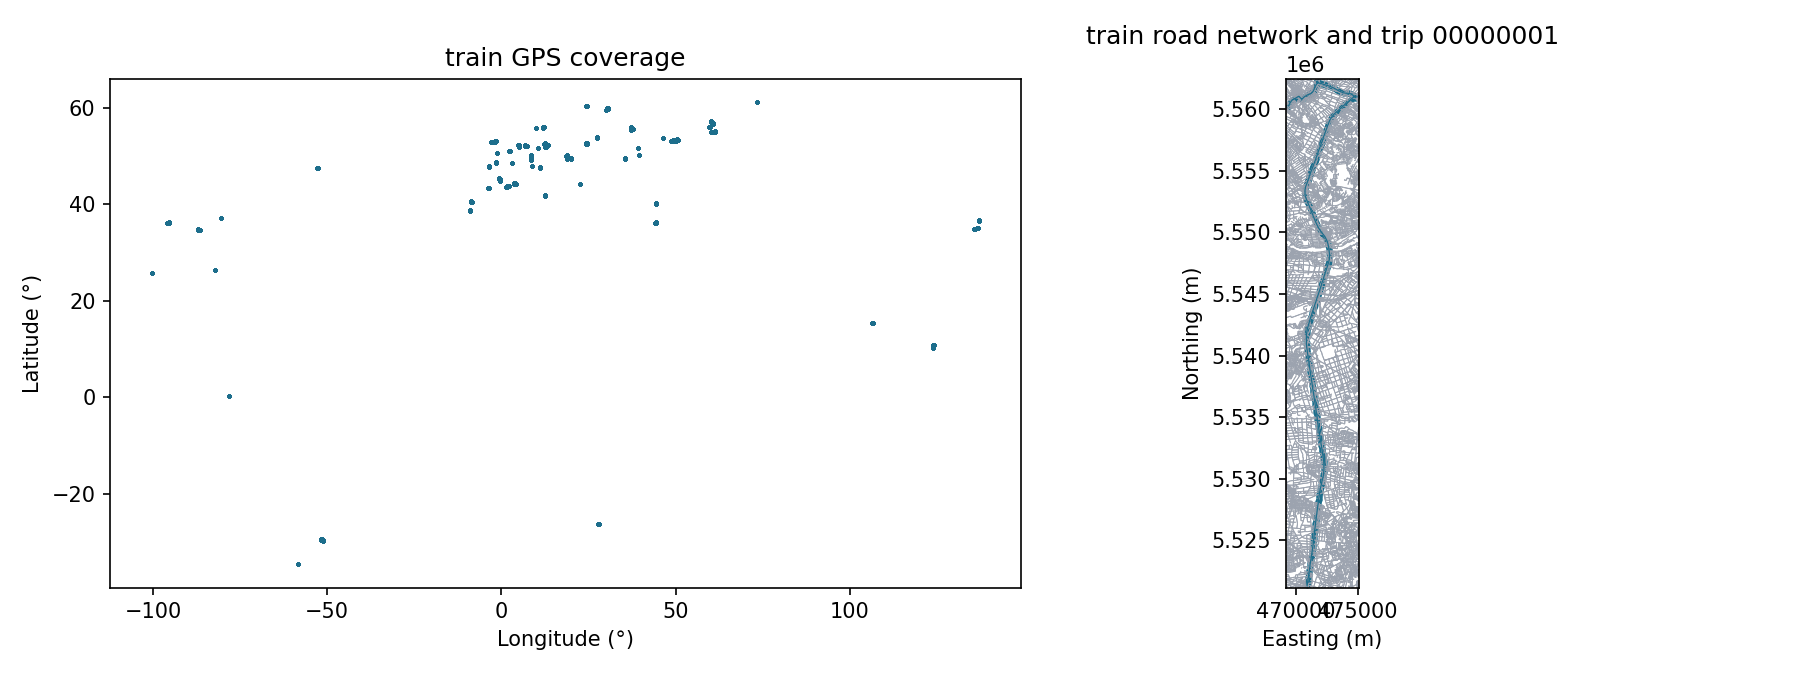

eda_gps_noise_student_test.png


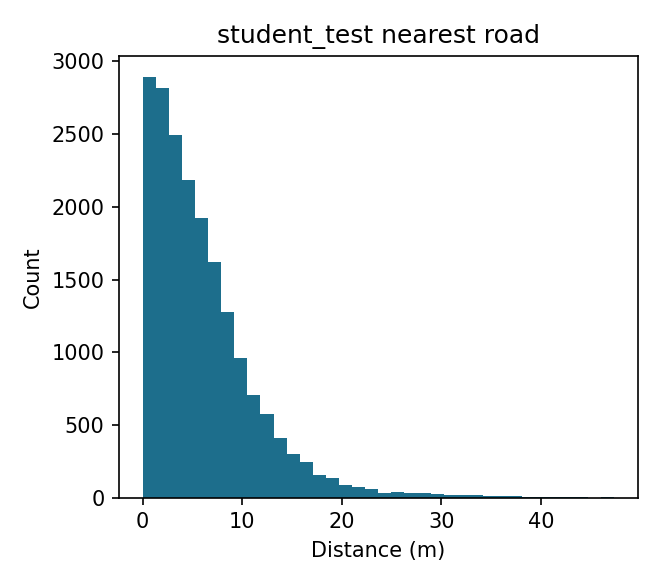

eda_gps_noise_train.png


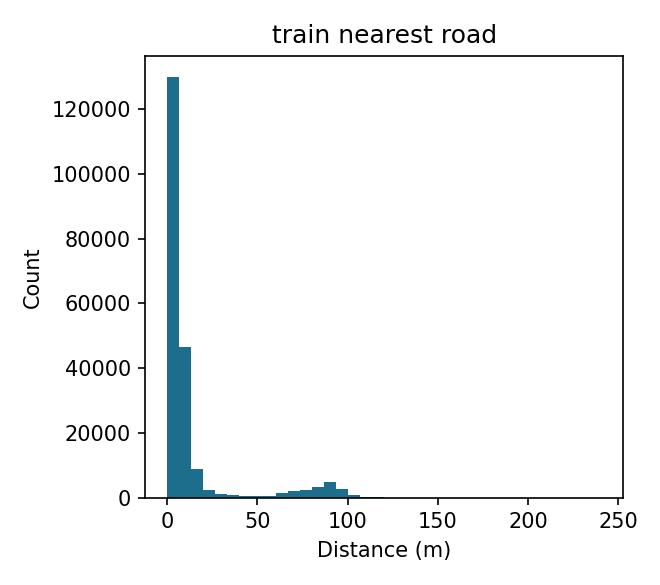

eda_network_student_test.png


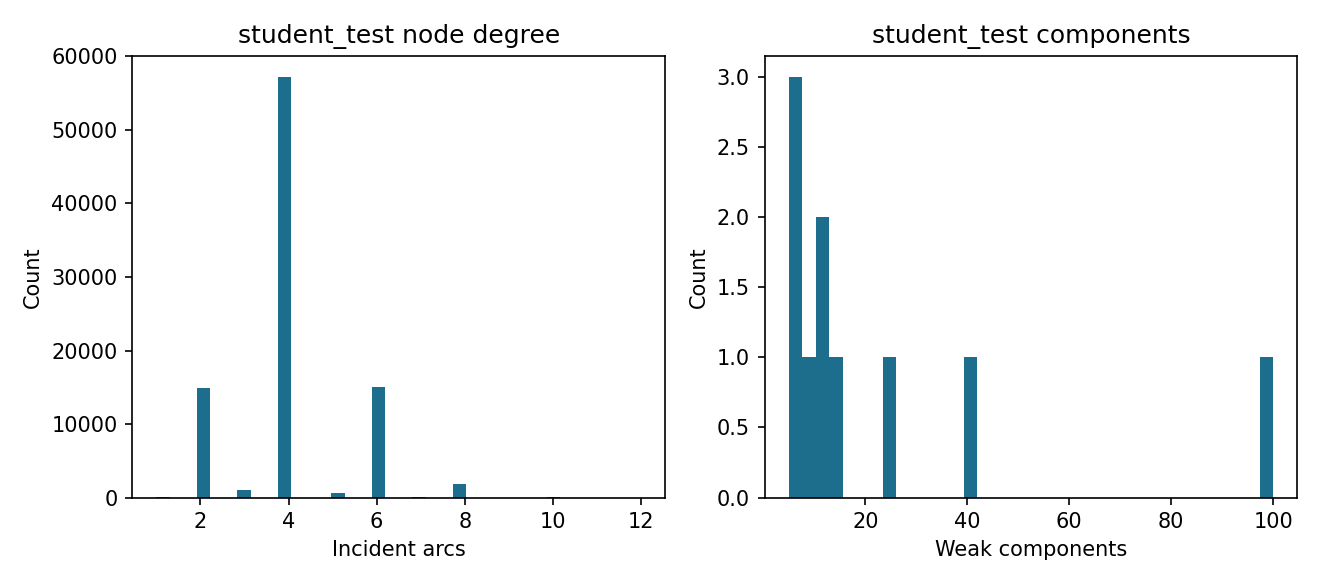

eda_network_train.png


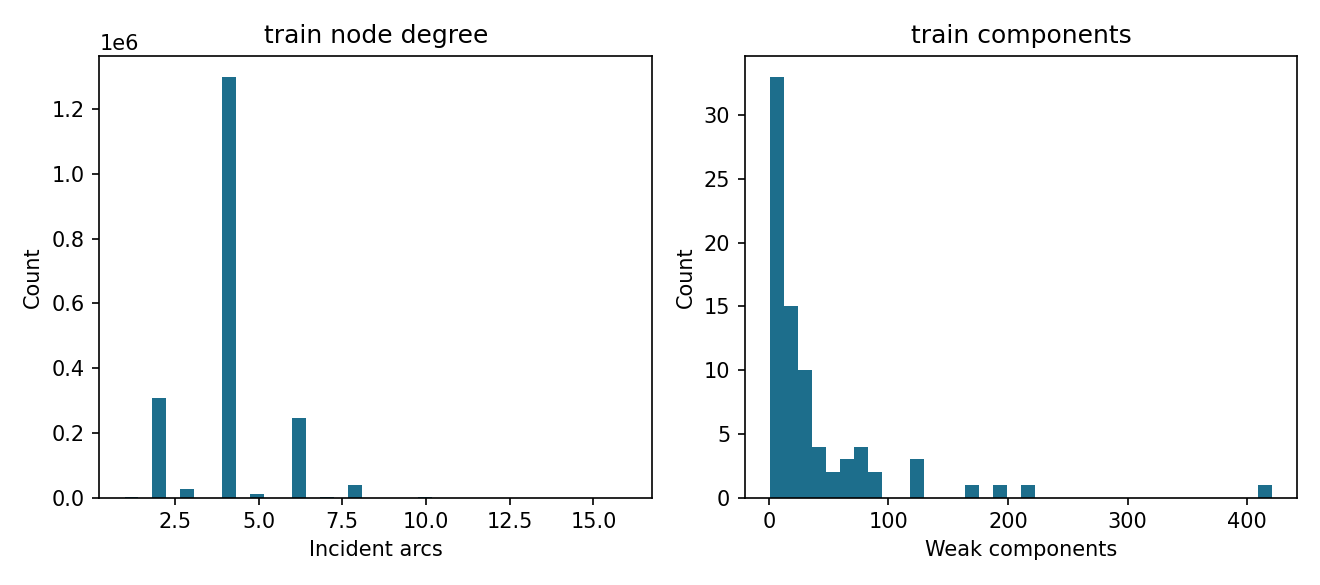

eda_time_gaps_student_test.png


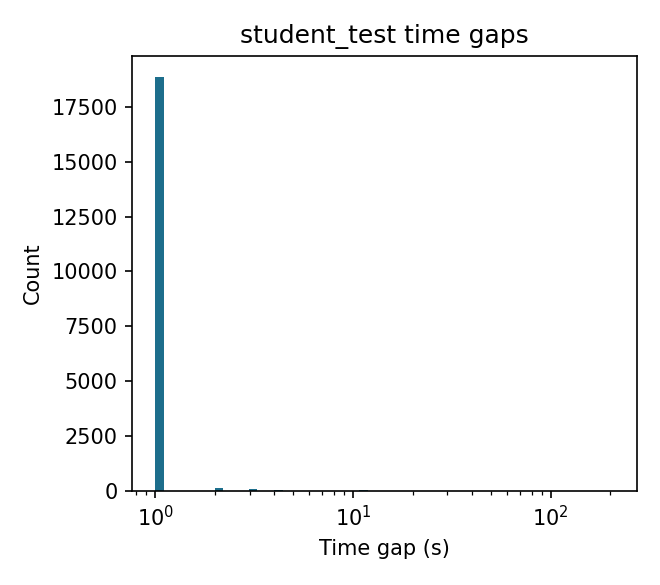

eda_time_gaps_train.png


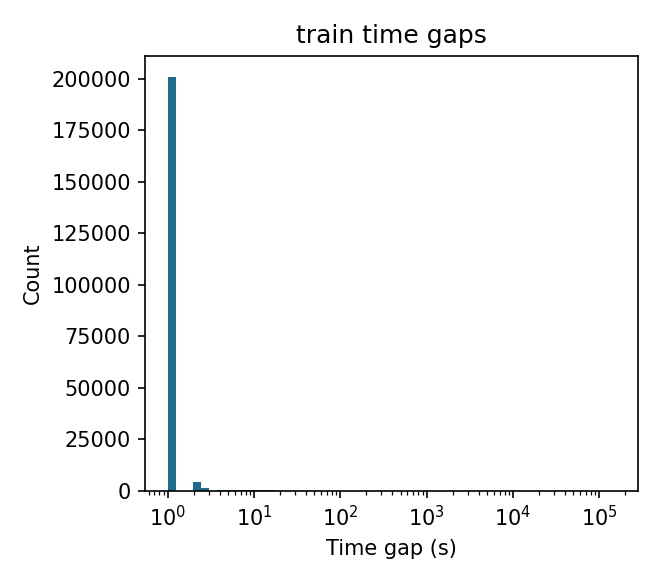

eda_trip_stats_student_test.png


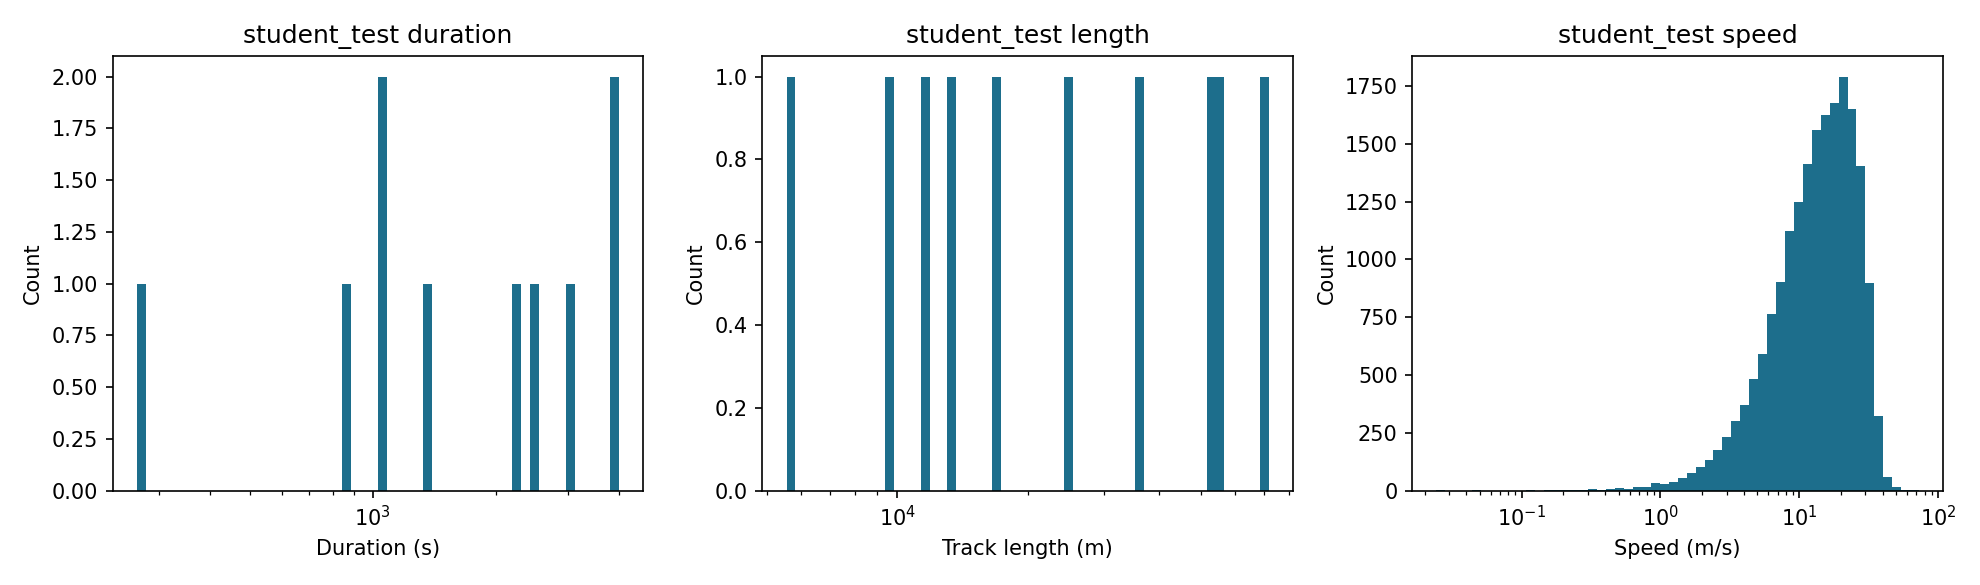

eda_trip_stats_train.png


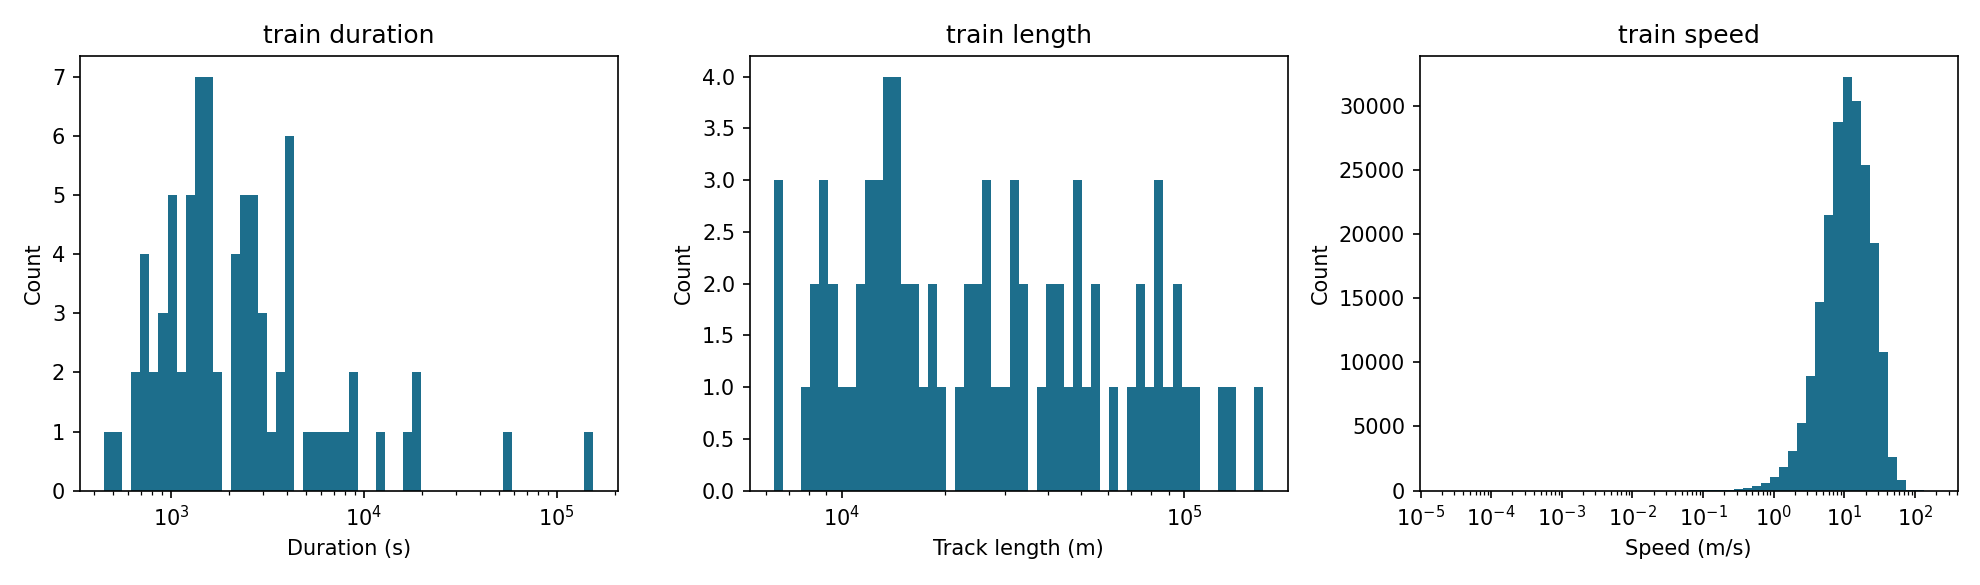

In [6]:
for f in sorted((RES / "eda/figures").glob("*.png")):
    print(f.name)
    show_png(f, 520)

## 6. Interactive Folium maps: GPS points, road network and reference route
The maps are generated by `visualisations/eda_map.py`; layers can be toggled in the top-right control.

In [7]:
from visualisations.eda_map import make_eda_map
_, p1 = make_eda_map("train", "00000001")
_, p2 = make_eda_map("student_test", "00000007")
print(p1.name, p2.name)
IFrame(src="../visualisations/maps/" + p2.name, width=900, height=520)

eda_train_00000001.html eda_student_test_00000007.html


## 7. Reference-label quality and candidate coverage per trip
The reference route is **reference information, not guaranteed ground truth**. Each GPS point is given one arc of its own route by a monotone dynamic programme; trips where the labelled arc is often far from the GPS points are flagged (`P95_FLAG_M` in `label_points.py`).

In [8]:
lq = pd.read_csv(RES / "eda/label_quality.csv", dtype={"trip": str})
print("flagged trips:", int(lq.flag_p95_gt_30.sum()), "of", len(lq))
display(lq[lq.flag_p95_gt_30])
cm = pd.read_csv(RES / "eda/candidate_miss_by_trip.csv", dtype={"trip_id": str})
tr = cm[cm.split == "train"]
pool = lambda d: (d.miss_rate * d.points).sum() / d.points.sum()
print(f"train candidate miss rate: all 80 trips {pool(tr):.4f} | unflagged {pool(tr[~tr.label_flagged]):.4f} | flagged only {pool(tr[tr.label_flagged]):.4f}")
print(f"student_test candidate miss rate: {pool(cm[cm.split == 'student_test']):.4f}")

flagged trips: 7 of 90


,split,trip,n_points,mean_dist_m,p95_dist_m,flag_p95_gt_30
1,train,00000002,7243,33.858,242.357,True
26,train,00000033,5844,81.025,142.059,True
35,train,00000043,2322,18.670,70.221,True
44,train,00000054,19313,134.922,210.051,True
53,train,00000066,4325,33.302,65.533,True
64,train,00000081,3224,10.470,44.556,True
67,train,00000084,16031,10.565,36.202,True


train candidate miss rate: all 80 trips 0.0790 | unflagged 0.0055 | flagged only 0.2682
student_test candidate miss rate: 0.0037


## 8. Data-quality record (assumptions and decisions)

In [9]:
display(Markdown((RES / "eda/data_quality.md").read_text()))

# Development data notes

- The archive contains 80 training trips and 10 student-test trips. The inventory counted 208,417 and 19,160 GPS observations, respectively.
- All 90 trips had their four expected files. The reference route is an arc sequence. The feature builder must align it to observations before creating candidate labels.
- The quality scan found no missing numeric values, invalid GPS coordinates, non-finite timestamps, or non-increasing time steps in either split.
- Using a numerical tolerance for one-second steps, 201,053 of 208,337 training intervals and 18,886 of 19,150 student-test intervals were one second.
- Gaps exceeded five seconds 1,216 times in training and 44 times in student testing. The maximum training gap was 153,064 seconds. The decoder should handle large gaps explicitly.
- There were multiple weakly connected graph components in 79 training trips and all 10 student-test trips. There were no isolated nodes under the incident-arc definition.
- Consecutive distinct reference arcs failed the directed endpoint check in 10 training trips and one student-test trip. The reference is useful for evaluation, with these discontinuities documented.
- Training nearest-road distances had a median of 4.97 m and a 95th percentile of 83.43 m. Student-test values were 4.76 m and 16.00 m. These distances use the nearest available segment. Candidate miss rate after reference alignment should guide radius and fallback decisions.
- Track step lengths use WGS84 geodesic distances. Nearest-segment distances use a per-trip UTM projection and full road segments.

Run `python -m visualisations.eda_plots` to regenerate the source tables and figures.


**Decisions taken from the EDA**
* Distances are computed in a per-trip UTM projection (metres), never in degrees.
* A road network is built **per trip**: every trip has its own `.nodes`/`.arcs`, so `arc_id` is only meaningful inside one trip.
* Most arcs have a reverse twin with identical geometry (see `network_check.txt` above), so distance alone cannot tell the two directions apart; a directed *heading* feature is needed.
* Large time gaps exist, so the decoder allows extra hops after a gap (`gap_s`).
* Some trips have unreliable reference tails; this is measured (section 7) and its effect on training is tested in notebook 03.